## ANN & Deep Learning
 Overview: Heart Disease Classification using Neural Network and AdaBoost

**Goal:** Build and compare two binary classifiers — a custom neural network and an AdaBoost ensemble — to predict presence/absence of heart disease using the UCI Cleveland Heart Disease dataset (303 patients, 13 features).

**What you'll do:**

1. **Setup** — Mount Google Drive and load the dataset (13 features + target; missing values expected in `ca` and `thal`).
2. **Explore the data** — Check shape, columns, dtypes, and summary statistics; understand what each feature and the target represent.
3. **Check class balance** — Count and visualize the target distribution, and determine whether the dataset is balanced or imbalanced.
4. **Assess data quality** — Identify missing values, duplicates, and unique value counts; decide how to handle missing data.
5. **Visualize** — Plot the target distribution, a couple of feature relationships, and a correlation heatmap.
6. **Preprocess** — Split features/target, separate numerical vs. categorical columns, impute missing values, encode categoricals, scale numerics, and split into train/test sets — all without leaking test data into training.
7. **Design a neural network** — Choose your own 4–5 layer architecture (neurons, activations) and record it in a table.
8. **Calculate parameters by hand** — Manually compute trainable parameters per layer using the standard formula, before verifying against Keras.
9. **Build and train the network** — Implement your design in Keras, choose a loss function and optimizer (with justification), compile, and train, tracking a validation split.
10. **Diagnose training** — Plot training vs. validation loss and comment on overfitting.
11. **Evaluate the network** — Compute accuracy, precision, recall, and F1-score on the test set.
12. **Build AdaBoost** — Train a second model (`AdaBoostClassifier`) and compute the same four metrics.
13. **Compare models** — Fill in a comparison table and discuss differences, likely causes, overfitting signs, and preprocessing impact.
14. **Wrap up** — Write a short final interpretation covering balance, preprocessing, your architecture, both models' results, the comparison, and possible improvements.

# Heart Disease Classification using Neural Network and AdaBoost

**Dataset:** UCI Heart Disease dataset (Cleveland / processed version)
**Source:** https://archive.ics.uci.edu/dataset/45/heart+disease

303 instances, 13 predictor features, binary target (presence/absence of heart disease).
Missing values are documented for the `ca` and `thal` columns.

> Before the lab: download the processed Cleveland dataset (`processed.cleveland.data` or the CSV version) and upload it to your Google Drive.



## Cell 1 — Mount Google Drive

In [ ]:
# Mount Google Drive to access the dataset
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

# Colab: put your Drive path here
# Local: the Cleveland file next to this notebook works too
DATA_PATH = "/content/drive/MyDrive/your_folder/processed.cleveland.data"

if not os.path.exists(DATA_PATH):
    DATA_PATH = "processed.cleveland.data"

print("Using:", DATA_PATH)

Using: processed.cleveland.data


## Cell 2 — Import Libraries

In [ ]:
# Core data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and model selection
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Ensemble model
from sklearn.ensemble import AdaBoostClassifier

# Evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Neural network
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
np.random.seed(42)
torch.manual_seed(42)

## Cell 3 — Load Dataset

In [ ]:
# UCI Cleveland file has no header and uses '?' for missing values
column_names = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"
]

df = pd.read_csv(DATA_PATH, header=None, names=column_names, na_values="?")

# Original target is 0-4. Make it binary: 0 = no disease, 1 = disease
df["target"] = (df["target"] > 0).astype(int)

print(df.shape)
df.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Cell 4 — Understand the Dataset

Explore the dataset and answer, in a markdown cell or comments below:
- How many samples and features are there?
- What are the column names and data types?
- What do the first 5 rows look like?
- What are the descriptive statistics (`describe()`)?
- What is the target variable and what values does it take?

In [ ]:
print("Shape (rows, columns):", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nFirst 5 rows:")
display(df.head())
print("\nDescriptive statistics:")
display(df.describe())
print("\nTarget value counts:")
print(df["target"].value_counts())

Shape (rows, columns): (303, 14)

Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Data types:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object

First 5 rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



Descriptive statistics:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.458746
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,0.499120
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,1.000000



Target value counts:
target
0    164
1    139
Name: count, dtype: int64


**Notes from Cell 4**

There are 303 samples and 14 columns (13 features + target).

Some features look continuous (age, chol, thalach, oldpeak). Others look more like categories (sex, cp, fbs, restecg, exang, slope, ca, thal).

The target is binary after cleaning: 0 means no heart disease, 1 means heart disease is present.

## Cell 5 — Check Balanced vs. Imbalanced Data

Investigate the target variable:
- Count of each class
- Percentage of each class
- Plot the target distribution
- State whether the dataset is balanced or imbalanced, and briefly explain why.

Class counts:
target
0    164
1    139
Name: count, dtype: int64

Class percentages:
target
0    54.13
1    45.87
Name: proportion, dtype: float64


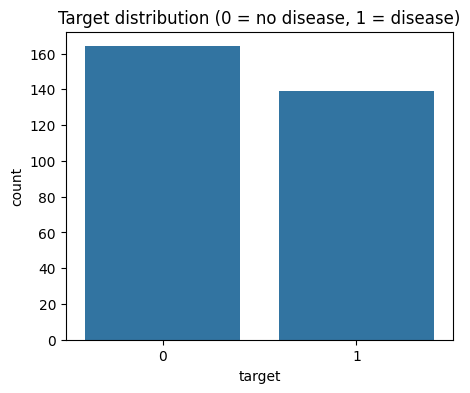

In [ ]:
counts = df["target"].value_counts().sort_index()
percents = df["target"].value_counts(normalize=True).sort_index() * 100

print("Class counts:")
print(counts)
print("\nClass percentages:")
print(percents.round(2))

plt.figure(figsize=(5, 4))
sns.countplot(x="target", data=df)
plt.title("Target distribution (0 = no disease, 1 = disease)")
plt.xlabel("target")
plt.ylabel("count")
plt.show()

**Balance check**

Class 0 has 164 samples (about 54%) and class 1 has 139 samples (about 46%).
That is close enough that I would call the dataset roughly balanced. Neither class is rare.

## Cell 6 — Missing Values and Data Quality

Check the dataset for:
- Missing / null values (remember '?' may need to be converted to NaN first)
- Duplicate rows
- Data types of each column
- Unique values per column

Identify which columns have missing values and decide how you will handle them (this decision is used later in preprocessing).

In [ ]:
print("Missing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nUnique values per column:")
print(df.nunique())

Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Duplicate rows: 0

Data types:
age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object

Unique values per column:
age          41
sex           2
cp            4
trestbps     50
chol        152
fbs           2
restecg       3
thalach      91
exang         2
oldpeak      40
slope         3
ca            4
thal          3
target        2
dtype: int64


**Data quality notes**

`ca` and `thal` have missing values (the original file used `?`). Other columns look complete. There are no duplicate rows.

How I will handle missing values later:
- numeric columns: fill with the median
- categorical columns: fill with the most frequent value

I will do this inside a pipeline fitted only on training data so the test set stays clean.

## Cell 7 — Data Visualization

Create and briefly interpret:
- Target distribution plot
- At least 2 additional visualizations of your choice (e.g. age distribution, feature vs. target)
- Correlation heatmap of numerical features

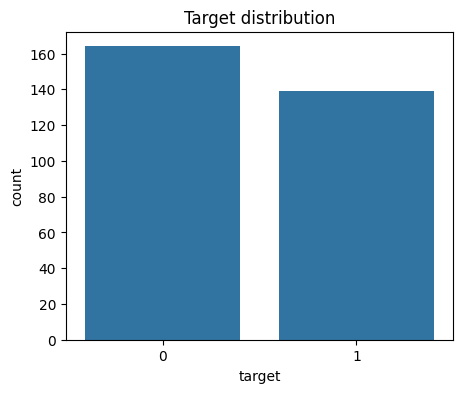

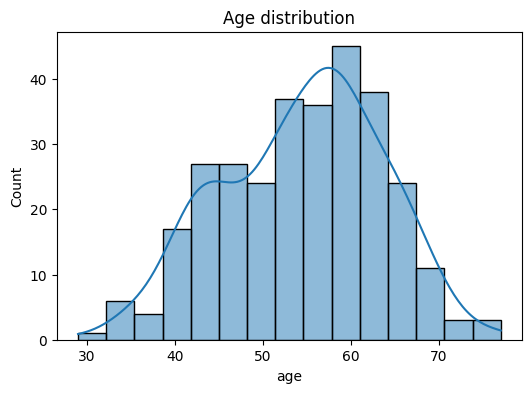

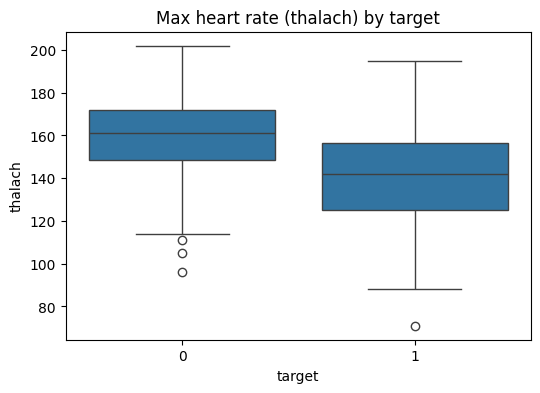

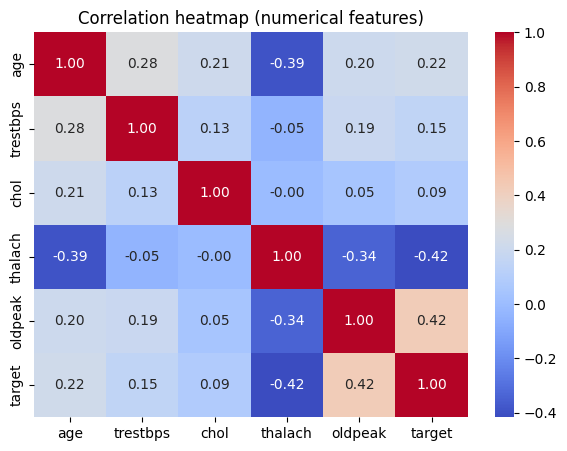

In [ ]:
# 1) Target distribution
plt.figure(figsize=(5, 4))
sns.countplot(x="target", data=df)
plt.title("Target distribution")
plt.show()

# 2) Age distribution
plt.figure(figsize=(6, 4))
sns.histplot(df["age"], bins=15, kde=True)
plt.title("Age distribution")
plt.xlabel("age")
plt.show()

# 3) Max heart rate vs target
plt.figure(figsize=(6, 4))
sns.boxplot(x="target", y="thalach", data=df)
plt.title("Max heart rate (thalach) by target")
plt.show()

# 4) Correlation heatmap for numerical features
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak", "target"]
plt.figure(figsize=(7, 5))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap (numerical features)")
plt.show()

**Visualization notes**

The target plot matches the counts from Cell 5.

Ages are mostly in middle age to older adults, which makes sense for this medical dataset.

People with disease (target=1) tend to have a lower max heart rate (`thalach`) in the boxplot.

On the heatmap, `oldpeak` has a positive correlation with the target and `thalach` has a negative one. Those two look useful for the model.

## Cell 8 — Preprocessing

- Separate features `X` and target `y`
- Identify numerical and categorical features
- Handle missing values (based on your Cell 6 decision)
- Encode categorical variables
- Scale numerical features where appropriate
- Split into training and testing sets

Build a preprocessing pipeline (e.g. `ColumnTransformer`) and fit it only on the training data to avoid data leakage.

In [ ]:
# Features and target
X = df.drop(columns=["target"])
y = df["target"]

# Column groups
numeric_features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_features = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

# 80% train+val, 20% test
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# From the 80%, take 10% as validation -> about 72% train, 8% val, 20% test
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.10, random_state=42, stratify=y_temp
)

print("Train size:", X_train.shape[0])
print("Val size  :", X_val.shape[0])
print("Test size :", X_test.shape[0])

# Numeric pipeline: median impute + scale
numeric_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical pipeline: most_frequent impute + one-hot
categorical_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocess = ColumnTransformer(transformers=[
    ("num", numeric_pipe, numeric_features),
    ("cat", categorical_pipe, categorical_features)
])

# Fit ONLY on train, then transform val and test
X_train_p = preprocess.fit_transform(X_train)
X_val_p = preprocess.transform(X_val)
X_test_p = preprocess.transform(X_test)

print("Processed feature count (input_dim):", X_train_p.shape[1])

# Convert to tensors (float labels for BCEWithLogitsLoss)
X_train_t = torch.tensor(X_train_p, dtype=torch.float32)
X_val_t = torch.tensor(X_val_p, dtype=torch.float32)
X_test_t = torch.tensor(X_test_p, dtype=torch.float32)

y_train_t = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)
y_val_t = torch.tensor(y_val.values, dtype=torch.float32).view(-1, 1)
y_test_t = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

Train size: 217
Val size  : 25
Test size : 61
Processed feature count (input_dim): 28


In [ ]:
# Create TensorDatasets
train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)
test_dataset = TensorDataset(X_test_t, y_test_t)

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print("DataLoaders ready.")

DataLoaders ready.


## Cell 9 — Design Your Own Neural Network

Design a neural network with **4-5 layers total** (input + hidden layers + output). Decide the number of neurons, hidden layers, and activation functions.

Fill in the table with your design:

| Layer    | Neurons | Activation |
|----------|--------:|------------|
| Input    | input_dim (after one-hot, printed above) | - |
| Hidden 1 | 32 | ReLU |
| Hidden 2 | 16 | ReLU |
| Hidden 3 | 8 | ReLU |
| Output   | 1 | none (raw logit for BCEWithLogitsLoss) |

I kept it small because the dataset only has 303 rows. Three hidden layers with fewer neurons each time seemed like a simple starting point.

## Cell 10 — Manually Calculate Parameters

For **each layer** in your design above, manually calculate the number of trainable parameters using:

`Parameters = (Input units × Output units) + Output units`

With `input_dim = 28` after one-hot:

| Layer    | Input Units | Output Units | Calculation | Parameters |
|----------|------------:|-------------:|-------------|-----------:|
| Hidden 1 | 28 | 32 | (28 × 32) + 32 | 928 |
| Hidden 2 | 32 | 16 | (32 × 16) + 16 | 528 |
| Hidden 3 | 16 | 8 | (16 × 8) + 8 | 136 |
| Output   | 8 | 1 | (8 × 1) + 1 | 9 |
| **Total**|  |  | 928 + 528 + 136 + 9 | **1601** |

This matches the printed `Trainable parameters: 1601` from Cell 11.

## Cell 11 — Implement Neural Network in PyTorch


In [ ]:
input_dim = X_train_p.shape[1]

class MyModel(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        # Simple feedforward network: input -> 32 -> 16 -> 8 -> 1
        self.model = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 1)
        )

    def forward(self, x):
        return self.model(x)


model = MyModel(input_dim=input_dim)
print(model)

# Check parameter count against hand calculation
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("input_dim:", input_dim)
print("Trainable parameters:", total_params)
print("Hand check Hidden1 =", (input_dim * 32) + 32)
print("Hand check total =", ((input_dim * 32) + 32) + 528 + 136 + 9)

MyModel(
  (model): Sequential(
    (0): Linear(in_features=28, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=8, bias=True)
    (5): ReLU()
    (6): Linear(in_features=8, out_features=1, bias=True)
  )
)
input_dim: 28
Trainable parameters: 1601
Hand check Hidden1 = 928
Hand check total = 1601


## Cell 12 — Choose Loss Function

Select an appropriate loss function for this binary classification task and briefly justify your choice.

I used `BCEWithLogitsLoss` because the task is binary (0 vs 1) and the model outputs one logit. This loss applies sigmoid inside, which is safer numerically than doing sigmoid then BCE by hand.

In [ ]:
loss_function = nn.BCEWithLogitsLoss()
print(loss_function)

BCEWithLogitsLoss()


## Cell 13 — Choose Optimizer

Choose an optimizer and briefly justify your choice.

I used Adam with learning rate 0.001. It is a common default for small networks and usually needs less manual tuning than plain SGD.

In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
print(optimizer)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


## Cell 14 — Train the Model

Train for several epochs. Each epoch updates weights on the training set, then we check average loss on the validation set (no weight updates there).

In [ ]:
num_epochs = 80
train_losses = []
val_losses = []

for epoch in range(num_epochs):

    # ---- training ----
    model.train()
    running_train_loss = 0.0

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()

        outputs = model(X_batch)
        loss = loss_function(outputs, y_batch)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * X_batch.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)

    # ---- validation (no updates) ----
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            outputs = model(X_batch)
            loss = loss_function(outputs, y_batch)
            running_val_loss += loss.item() * X_batch.size(0)

    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    val_losses.append(epoch_val_loss)

    # print every 10 epochs so the output is not too long
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(
            f"Epoch {epoch+1:3d}/{num_epochs}  "
            f"train_loss={epoch_train_loss:.4f}  "
            f"val_loss={epoch_val_loss:.4f}"
        )

print("Training finished.")

Epoch   1/80  train_loss=0.6930  val_loss=0.6847
Epoch  10/80  train_loss=0.5778  val_loss=0.5549
Epoch  20/80  train_loss=0.3459  val_loss=0.3196
Epoch  30/80  train_loss=0.3075  val_loss=0.3133
Epoch  40/80  train_loss=0.2811  val_loss=0.2960
Epoch  50/80  train_loss=0.2560  val_loss=0.3262
Epoch  60/80  train_loss=0.2366  val_loss=0.3330
Epoch  70/80  train_loss=0.2104  val_loss=0.4026
Epoch  80/80  train_loss=0.1802  val_loss=0.4117
Training finished.


## Cell 15 — Plot Training and Validation Loss

Plot training loss vs. validation loss across epochs, then briefly comment on whether there are signs of overfitting.

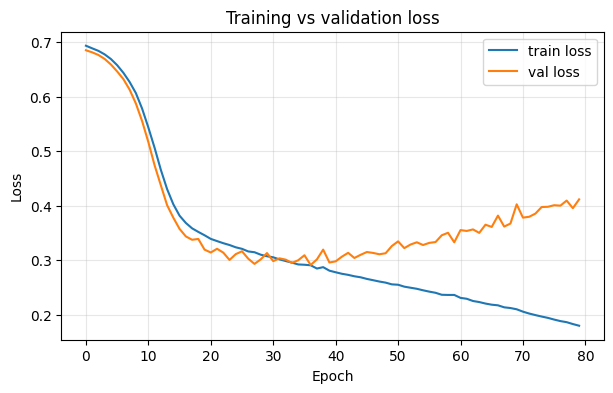

Final train loss: 0.1802
Final val loss  : 0.4117


In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(train_losses, label="train loss")
plt.plot(val_losses, label="val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs validation loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print("Final train loss:", round(train_losses[-1], 4))
print("Final val loss  :", round(val_losses[-1], 4))

**Overfitting comment**

Both losses drop together early on. By epoch 40, train loss is about 0.28 and val loss is about 0.30. After that, train loss keeps falling (down to 0.18 at epoch 80) while val loss rises again (up to 0.41).

That gap means the network is starting to overfit the training set. Stopping around epoch 40, or using early stopping, would probably help.

## Extra check — early stopping

After looking at the plot above, I noticed the model was overfitting (train loss kept falling while val loss went back up after about epoch 40).

So I tried the same network again, but this time with early stopping: stop when validation loss does not improve for 10 epochs in a row, then keep the best weights.

In [ ]:
# Same architecture, fresh weights, early stopping on val loss
torch.manual_seed(42)
np.random.seed(42)

model_es = MyModel(input_dim=input_dim)
optimizer_es = torch.optim.Adam(model_es.parameters(), lr=0.001)

num_epochs_es = 80
patience = 10
best_val = float("inf")
wait = 0
best_state = None
best_epoch = 0

train_losses_es = []
val_losses_es = []

for epoch in range(num_epochs_es):

    # ---- training ----
    model_es.train()
    running_train_loss = 0.0

    for X_batch, y_batch in train_loader:
        optimizer_es.zero_grad()
        outputs = model_es(X_batch)
        loss = loss_function(outputs, y_batch)
        loss.backward()
        optimizer_es.step()
        running_train_loss += loss.item() * X_batch.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    train_losses_es.append(epoch_train_loss)

    # ---- validation ----
    model_es.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            outputs = model_es(X_batch)
            loss = loss_function(outputs, y_batch)
            running_val_loss += loss.item() * X_batch.size(0)

    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    val_losses_es.append(epoch_val_loss)

    # check if this is the best val loss so far
    if epoch_val_loss < best_val:
        best_val = epoch_val_loss
        best_epoch = epoch + 1
        wait = 0
        # save a copy of the best weights
        best_state = {k: v.detach().cpu().clone() for k, v in model_es.state_dict().items()}
    else:
        wait += 1

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(
            f"Epoch {epoch+1:3d}/{num_epochs_es}  "
            f"train_loss={epoch_train_loss:.4f}  "
            f"val_loss={epoch_val_loss:.4f}  "
            f"wait={wait}/{patience}"
        )

    if wait >= patience:
        print(f"\nEarly stopping at epoch {epoch+1} (no val improvement for {patience} epochs)")
        break

# load the best weights back into the model
model_es.load_state_dict(best_state)
print(f"Best epoch: {best_epoch}")
print(f"Best val loss: {best_val:.4f}")
print(f"Epochs actually run: {len(train_losses_es)}")


Epoch   1/80  train_loss=0.6930  val_loss=0.6847  wait=0/10
Epoch  10/80  train_loss=0.5778  val_loss=0.5549  wait=0/10
Epoch  20/80  train_loss=0.3459  val_loss=0.3196  wait=0/10
Epoch  30/80  train_loss=0.3075  val_loss=0.3133  wait=2/10
Epoch  40/80  train_loss=0.2811  val_loss=0.2960  wait=3/10

Early stopping at epoch 47 (no val improvement for 10 epochs)
Best epoch: 37
Best val loss: 0.2914
Epochs actually run: 47


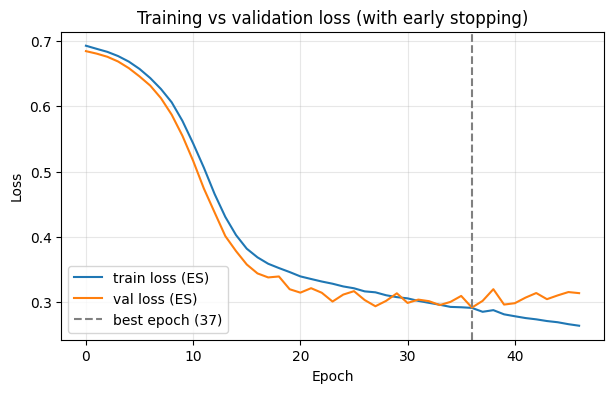

In [ ]:
# Loss curves for the early-stopping run only
plt.figure(figsize=(7, 4))
plt.plot(train_losses_es, label="train loss (ES)")
plt.plot(val_losses_es, label="val loss (ES)")
plt.axvline(best_epoch - 1, color="gray", linestyle="--", label=f"best epoch ({best_epoch})")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs validation loss (with early stopping)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# Test metrics for the early-stopped model (separate from the original model)
model_es.eval()

y_true_es = []
y_prob_es = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        outputs = model_es(X_batch)
        probabilities = torch.sigmoid(outputs).squeeze()

        if probabilities.ndim == 0:
            y_prob_es.append(probabilities.item())
            y_true_es.append(y_batch.item())
        else:
            y_prob_es.extend(probabilities.cpu().numpy().tolist())
            y_true_es.extend(y_batch.cpu().numpy().reshape(-1).tolist())

y_pred_es = [1 if p >= 0.5 else 0 for p in y_prob_es]

nn_es_accuracy = accuracy_score(y_true_es, y_pred_es)
nn_es_precision = precision_score(y_true_es, y_pred_es, zero_division=0)
nn_es_recall = recall_score(y_true_es, y_pred_es, zero_division=0)
nn_es_f1 = f1_score(y_true_es, y_pred_es, zero_division=0)

print("Neural net WITH early stopping (test set):")
print(f"Accuracy : {nn_es_accuracy:.4f}")
print(f"Precision: {nn_es_precision:.4f}")
print(f"Recall   : {nn_es_recall:.4f}")
print(f"F1-score : {nn_es_f1:.4f}")

Neural net WITH early stopping (test set):
Accuracy : 0.8852
Precision: 0.8387
Recall   : 0.9286
F1-score : 0.8814


**Early stopping note**

Training stopped at epoch 47 because val loss had not improved for 10 epochs. The best weights were from epoch 37 (val loss 0.2914), which is right around where the first run started overfitting.

On the test set, early stopping kept the same accuracy (0.8852) but changed the other scores a bit: precision went down to 0.8387, recall went up to 0.9286, and F1 edged up to 0.8814. So it catches a few more disease cases and makes a few more false positives, while avoiding the later overfit stage of the 80-epoch run.

## Cell 17 — Evaluate Neural Network

Make predictions on the test set and calculate accuracy, precision, recall, and F1-score.

In [ ]:
model.eval()

y_true = []
y_prob = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        outputs = model(X_batch)
        # model outputs logits; turn them into probabilities
        probabilities = torch.sigmoid(outputs).squeeze()

        # handle single-sample batches cleanly
        if probabilities.ndim == 0:
            y_prob.append(probabilities.item())
            y_true.append(y_batch.item())
        else:
            y_prob.extend(probabilities.cpu().numpy().tolist())
            y_true.extend(y_batch.cpu().numpy().reshape(-1).tolist())

threshold = 0.5
y_pred_nn = [1 if p >= threshold else 0 for p in y_prob]

nn_accuracy = accuracy_score(y_true, y_pred_nn)
nn_precision = precision_score(y_true, y_pred_nn, zero_division=0)
nn_recall = recall_score(y_true, y_pred_nn, zero_division=0)
nn_f1 = f1_score(y_true, y_pred_nn, zero_division=0)

print(f"Accuracy : {nn_accuracy:.4f}")
print(f"Precision: {nn_precision:.4f}")
print(f"Recall   : {nn_recall:.4f}")
print(f"F1-score : {nn_f1:.4f}")

Accuracy : 0.8852
Precision: 0.8621
Recall   : 0.8929
F1-score : 0.8772


## Cell 18 — Build AdaBoost Classifier

Build a second model using `AdaBoostClassifier`:
- Create the model
- Train it
- Make predictions
- Calculate accuracy, precision, recall, and F1-score

In [ ]:
# Same preprocessed features as the neural net (already fit on train only)
ada_model = AdaBoostClassifier(n_estimators=50, random_state=42)
ada_model.fit(X_train_p, y_train.values)

y_pred_ada = ada_model.predict(X_test_p)

ada_accuracy = accuracy_score(y_test, y_pred_ada)
ada_precision = precision_score(y_test, y_pred_ada, zero_division=0)
ada_recall = recall_score(y_test, y_pred_ada, zero_division=0)
ada_f1 = f1_score(y_test, y_pred_ada, zero_division=0)

print(f"Accuracy : {ada_accuracy:.4f}")
print(f"Precision: {ada_precision:.4f}")
print(f"Recall   : {ada_recall:.4f}")
print(f"F1-score : {ada_f1:.4f}")

Accuracy : 0.8852
Precision: 0.8621
Recall   : 0.8929
F1-score : 0.8772


## Cell 19 — Compare Both Models

| Model          | Accuracy | Precision | Recall | F1-Score |
|----------------|---------:|----------:|-------:|---------:|
| Neural Network (80 epochs) | 0.8852 | 0.8621 | 0.8929 | 0.8772 |
| Neural Net + early stopping | 0.8852 | 0.8387 | 0.9286 | 0.8814 |
| AdaBoost       | 0.8852 | 0.8621 | 0.8929 | 0.8772 |

All three setups land on the same test accuracy (0.8852). The original neural net and AdaBoost also match on precision, recall, and F1.

Early stopping did not raise accuracy, but it did shift the tradeoff: recall is higher (0.9286 vs 0.8929) and precision is a bit lower (0.8387 vs 0.8621). F1 is slightly better (0.8814 vs 0.8772). That fits with stopping near epoch 37 instead of training through the overfit region after epoch 40.

The neural net can overfit if you train too long (val loss rose after ~epoch 40). AdaBoost is simpler and matched the full 80-epoch net here. Early stopping is a useful check when the loss plot starts to diverge.

Preprocessing mattered: median / most-frequent imputation, one-hot encoding, and scaling were fit on train only, then applied to val and test. Without that, missing `ca`/`thal` values and mixed feature scales would hurt the models.

In [ ]:
comparison = pd.DataFrame({
    "Model": [
        "Neural Network (80 epochs)",
        "Neural Net + early stopping",
        "AdaBoost"
    ],
    "Accuracy": [nn_accuracy, nn_es_accuracy, ada_accuracy],
    "Precision": [nn_precision, nn_es_precision, ada_precision],
    "Recall": [nn_recall, nn_es_recall, ada_recall],
    "F1-Score": [nn_f1, nn_es_f1, ada_f1]
})

display(comparison.round(4))


,Model,Accuracy,Precision,Recall,F1-Score
0,Neural Network (80 epochs),0.8852,0.8621,0.8929,0.8772
1,Neural Net + early stopping,0.8852,0.8387,0.9286,0.8814
2,AdaBoost,0.8852,0.8621,0.8929,0.8772


## Cell 20 — Final Interpretation

1. The dataset is roughly balanced: 164 no-disease (54.1%) and 139 disease (45.9%).

2. Main preprocessing steps: 80/20 stratified split, then 10% of the train portion held out as validation (217 / 25 / 61). Median impute + scaling for numeric columns. Most-frequent impute + one-hot for categorical columns. Pipeline fitted on train only (input_dim became 28).

3. Network design: 28 -> 32 -> 16 -> 8 -> 1 with ReLU in the hidden layers and a single logit output. Trainable parameters: 1601. Loss was BCEWithLogitsLoss. Optimizer was Adam (lr=0.001). First trained for 80 epochs.

4. Neural net (80 epochs) test results: accuracy 0.8852, precision 0.8621, recall 0.8929, F1 0.8772. Training showed overfitting after about epoch 40 (train loss kept falling, val loss rose to 0.41).

5. AdaBoost (50 estimators, seed 42) matched those same four metrics on the test set.

6. With early stopping (patience 10), training stopped at epoch 47 and kept the best weights from epoch 37 (val loss 0.2914). Test scores: accuracy 0.8852, precision 0.8387, recall 0.9286, F1 0.8814. Same accuracy as before, higher recall and F1, slightly lower precision.

7. Overall, all three setups hit 88.5% accuracy. AdaBoost is the simplest. The neural net needs care on training length. Early stopping did not boost accuracy here, but it avoided the late overfit stage and pushed recall up a bit.

8. Possible next steps: a bit of dropout, different hidden sizes, or tuning AdaBoost's n_estimators. A larger medical dataset would also make the comparison more stable.